# Choosing the smoothing parameter

This notebook compares **classical in-sample CV, GCV, AICc, and BIC** as implemented by the library. These scores choose a smoother; they do **not** evaluate future forecasting performance.

The reference mean $\mu$ is fixed at zero in all examples.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from trendestimation import TrendSmoother, select_lambda, plot_selection, plot_trend

rng = np.random.default_rng(7)
t = np.linspace(0, 1, 70)
y = 3 * t + 0.5 * np.sin(4 * np.pi * t) + rng.normal(0, 0.3, len(t))
solver = TrendSmoother(len(y), order=2)

## Compare four established criteria

All selectors evaluate the same series and differencing order. Finite penalty candidates are searched on a geometric grid; the infinite-penalty endpoint is also considered.

In [3]:
criteria = ["cv", "gcv", "aicc", "bic"]
results = {name: select_lambda(solver, y, criterion=name, mu=0.0) for name in criteria}
for name, result in results.items():
    print(f"{name.upper():>4}: lambda={result.lambda_:>12.4g}, smoothness={result.smoothness:.3f}")

  CV: lambda=       72.44, smoothness=0.888
 GCV: lambda=       77.84, smoothness=0.891
AICC: lambda=       97.99, smoothness=0.898
 BIC: lambda=   2.461e-07, smoothness=0.000


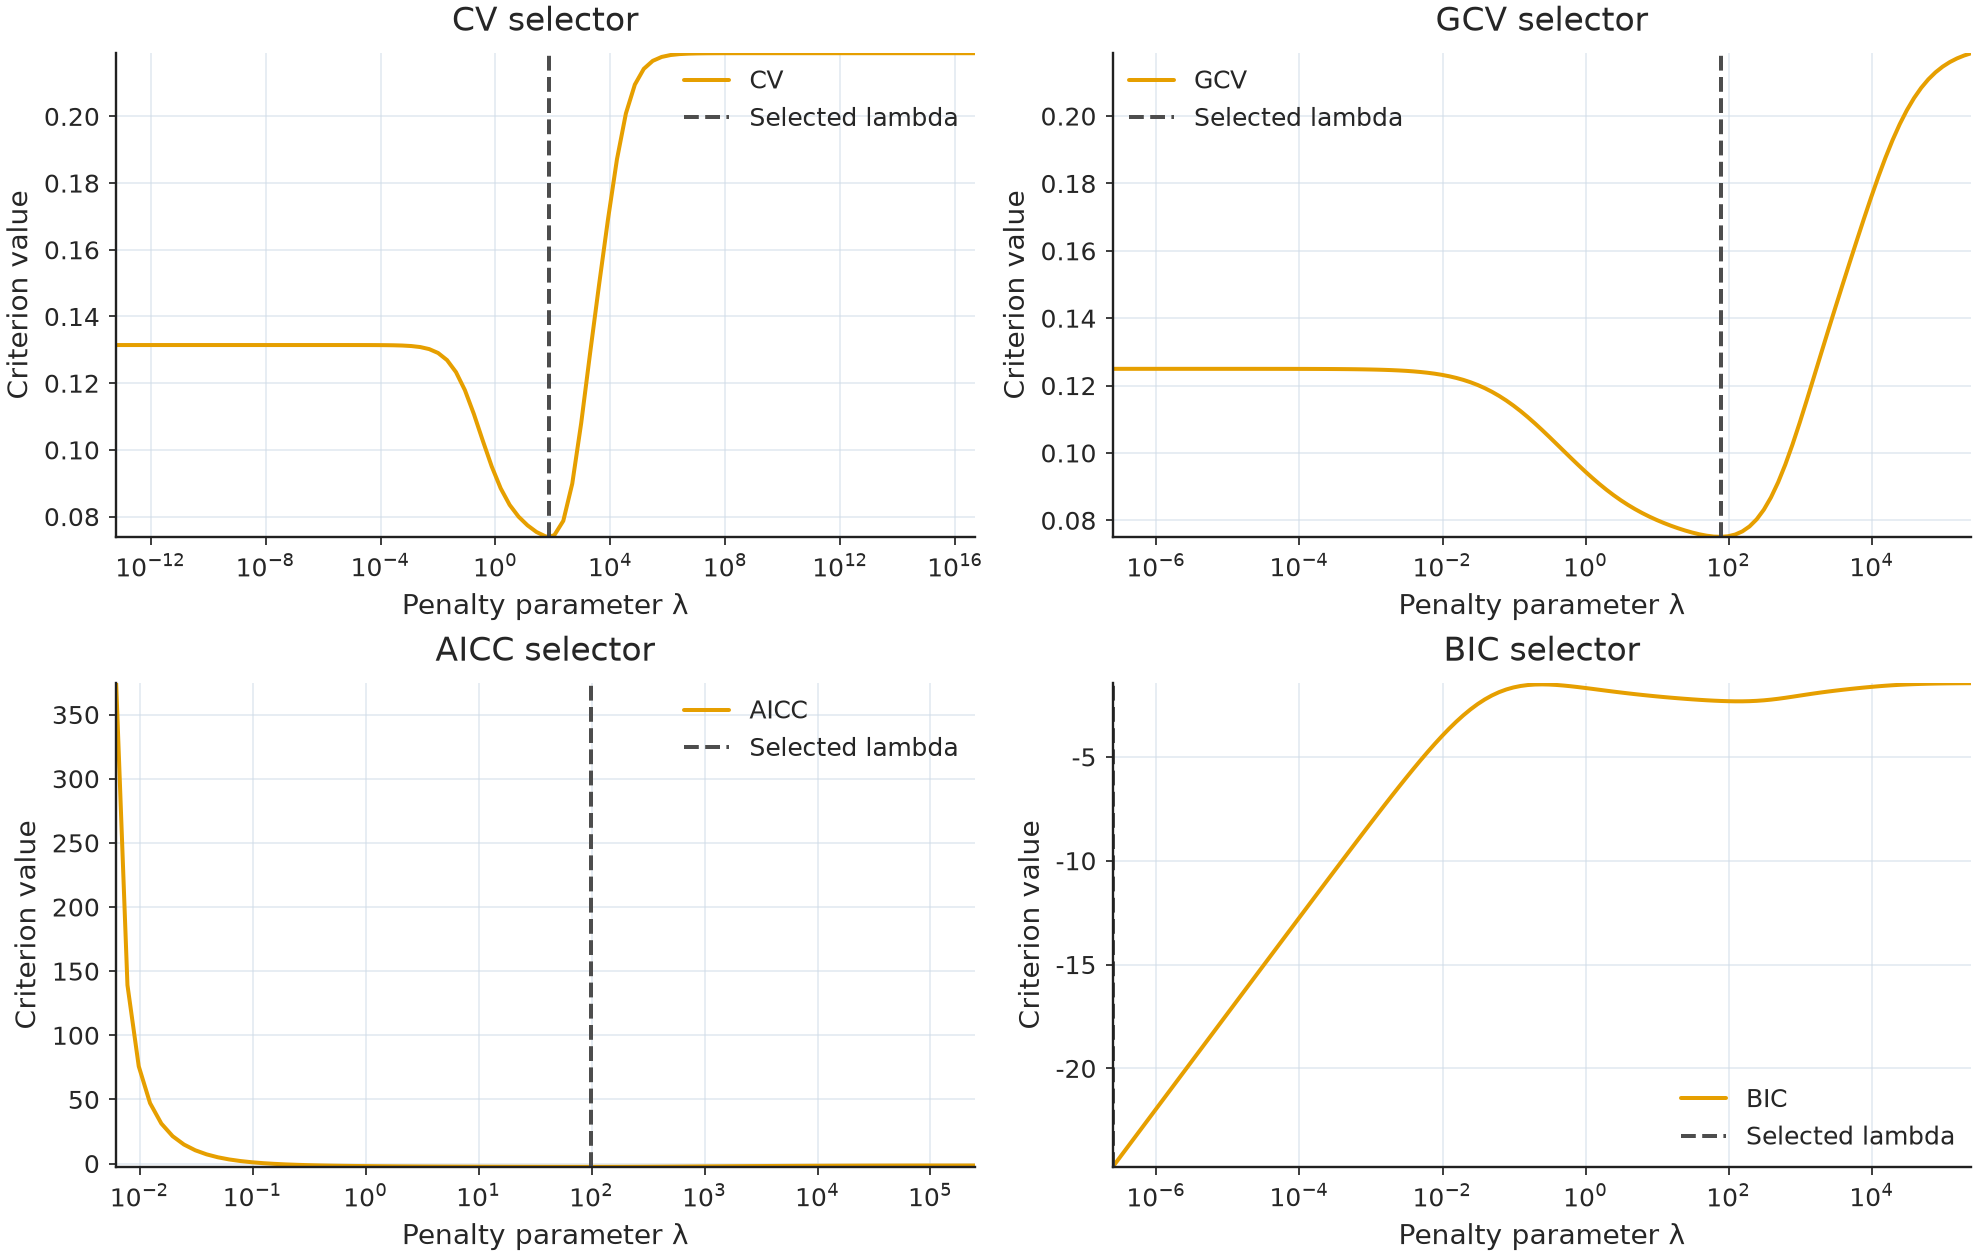

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for ax, name in zip(axes.flat, criteria):
    plot_selection(results[name], ax=ax)
    ax.set_title(f"{name.upper()} selector")
plt.show()

## Inspect the selected GCV trend

The [SelectionResult API](../api.rst) exposes the candidate penalties, scores, optimal penalty, and normalized smoothness. Different criteria need not select the same smoothing level.

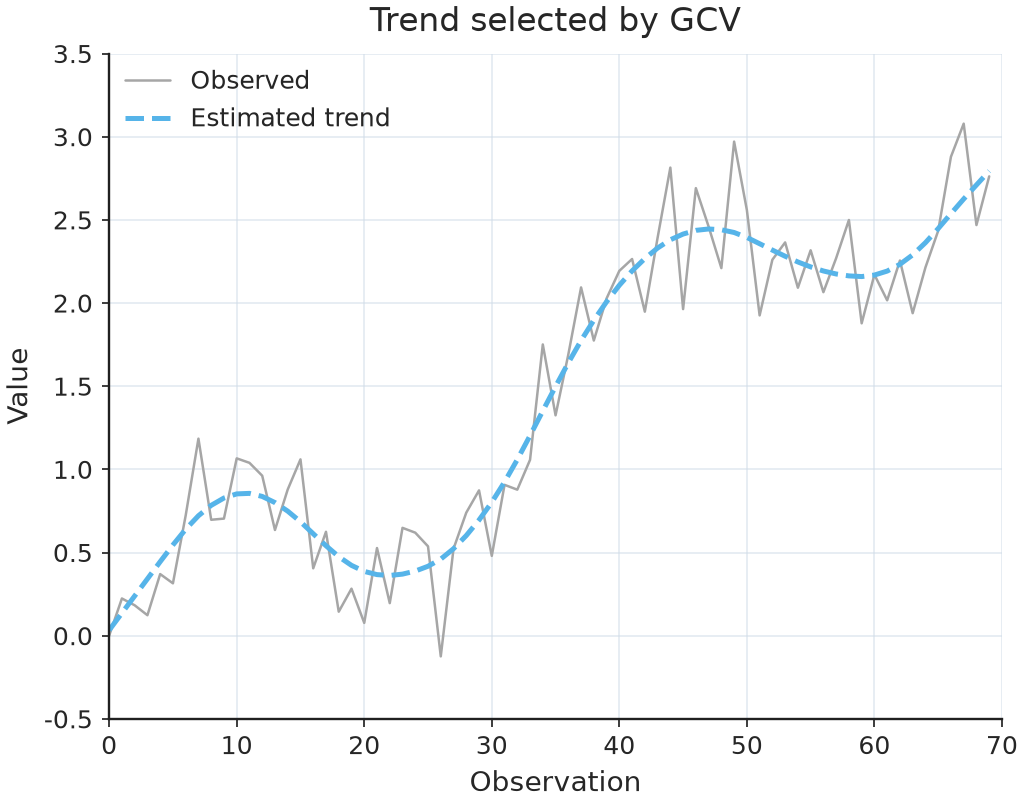

In [5]:
gcv = results["gcv"]
fit = solver.fit(y, lambda_=gcv.lambda_, mu=0.0)
plot_trend(y, fit, title="Trend selected by GCV")
plt.show()

## Important statistical boundary

For `mu="data"`, the reference mean is itself estimated from the observations. The package intentionally does **not** offer the classical selectors in that mode as exact leave-one-out calculations. Their direct formulas require **fixed numeric** $\mu$. The displayed criterion scores are in-sample smoothing diagnostics, not future prediction scores.

## Gaussian MLE: estimating the two variance components

Alongside these **four classical** criteria, the library provides a distinct Gaussian marginal-likelihood selector, `criterion="mle"`. It assumes independent observation noise with variance $\sigma_\varepsilon^2$ and latent second differences with variance $\sigma_\eta^2$, related through $\lambda=\sigma_\varepsilon^2/\sigma_\eta^2$. The estimated variances are **not** the sample variance of the fitted trend or the squared residual average. Here we keep $\mu=0$ fixed; `mu="data"` is also allowed for MLE but is only a conditional plug-in.


MLE lambda: 49.1129
Noise variance: 0.0646649
Second-difference variance: 0.00131666
Noise SD: 0.254293
Difference SD: 0.0362858


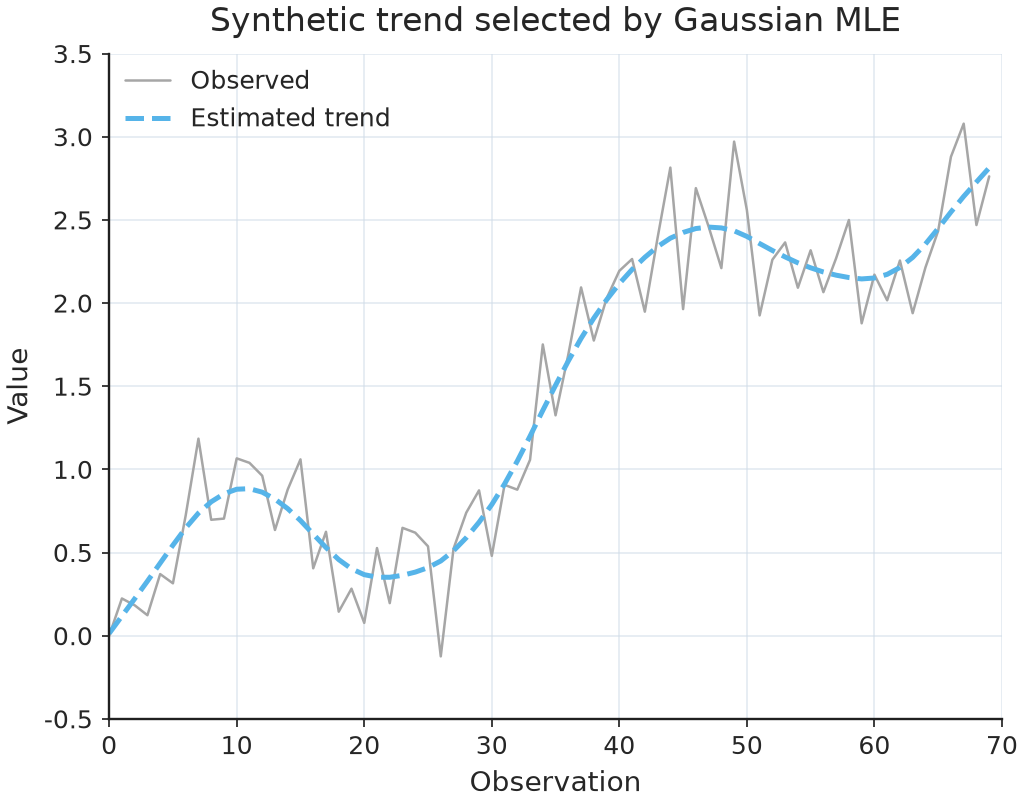

In [6]:
from trendestimation import estimate_variance_components

mle = select_lambda(solver, y, criterion="mle", mu=0.0)
components = estimate_variance_components(
    solver, y, lambda_=mle.lambda_, mu=0.0,
)
print(f"MLE lambda: {mle.lambda_:.6g}")
print(f"Noise variance: {components.observation_variance:.6g}")
print(f"Second-difference variance: {components.difference_variance:.6g}")
print(f"Noise SD: {components.observation_sd:.6g}")
print(f"Difference SD: {components.difference_sd:.6g}")
ax = plot_trend(y, solver.fit(y, lambda_=mle.lambda_, mu=0.0),
                title="Synthetic trend selected by Gaussian MLE")
plt.show()


**Model boundary:** MLE variance components are conditional on the chosen penalty and Gaussian assumptions, and do not provide forecast prediction intervals. See the [extended MLE notebook](../notebooks/09-gaussian-mle-and-guerrero-smoothness.ipynb) and the [API reference](../api.rst).


## Side-by-side penalty and normalized-smoothness coordinates

The following reproducible figures show the **same PLS estimator and fixed-mean CV/GCV/AICc/BIC scores** plotted against both the raw penalty $\lambda$ and normalized trace smoothness $S(\lambda)$. Both panels mark the same lowest-scoring **matched-grid** candidate. The final small timing chart runs the public GCV selector once in each coordinate. It is **illustrative only**, since the two default searches inspect different grids; controlled multi-seed timings belong to `benchmarks/criterion_coordinate_matrix.py` and `benchmarks/public_coordinate_optimizer_benchmark.py`.

Paired coordinates: last 60 observations of the notebook series; n=60, d=2, mu=0
Normalized S grid: [0.       0.1      0.2      0.3      0.4      0.5      0.6      0.7
 0.8      0.9      0.95     0.99     0.999    0.9999   0.999999 1.      ]
S=0 maps to lambda=0; S=1 maps to lambda=+infinity.
Near-1 targets: S=0.950000 -> lambda=886.169, S=0.990000 -> lambda=33003.8, S=0.999000 -> lambda=510198, S=0.999900 -> lambda=5.29957e+06, S=0.999999 -> lambda=5.32145e+08
Maximum inversion / round-trip error: 1.33e-15


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


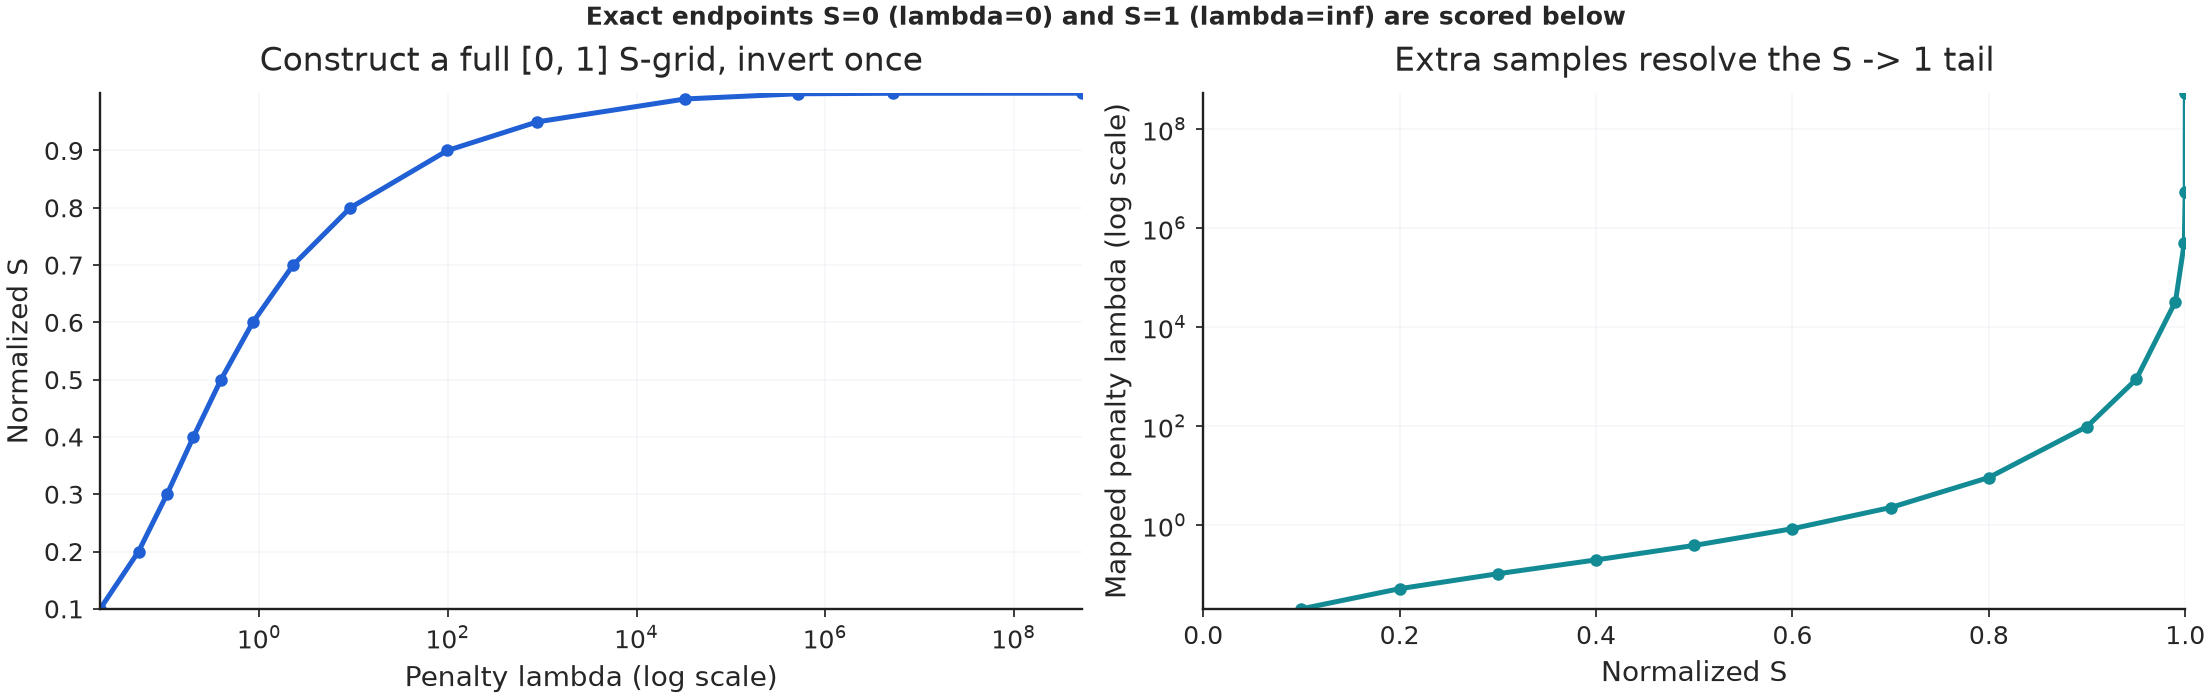

  CV: lambda=    98.7192, S=0.9, score=0.0759866
 GCV: lambda=    98.7192, S=0.9, score=0.0774147
AICC: lambda=    98.7192, S=0.9, score=-2.50643
 BIC: lambda=  0.0205109, S=0.1, score=-2.97532


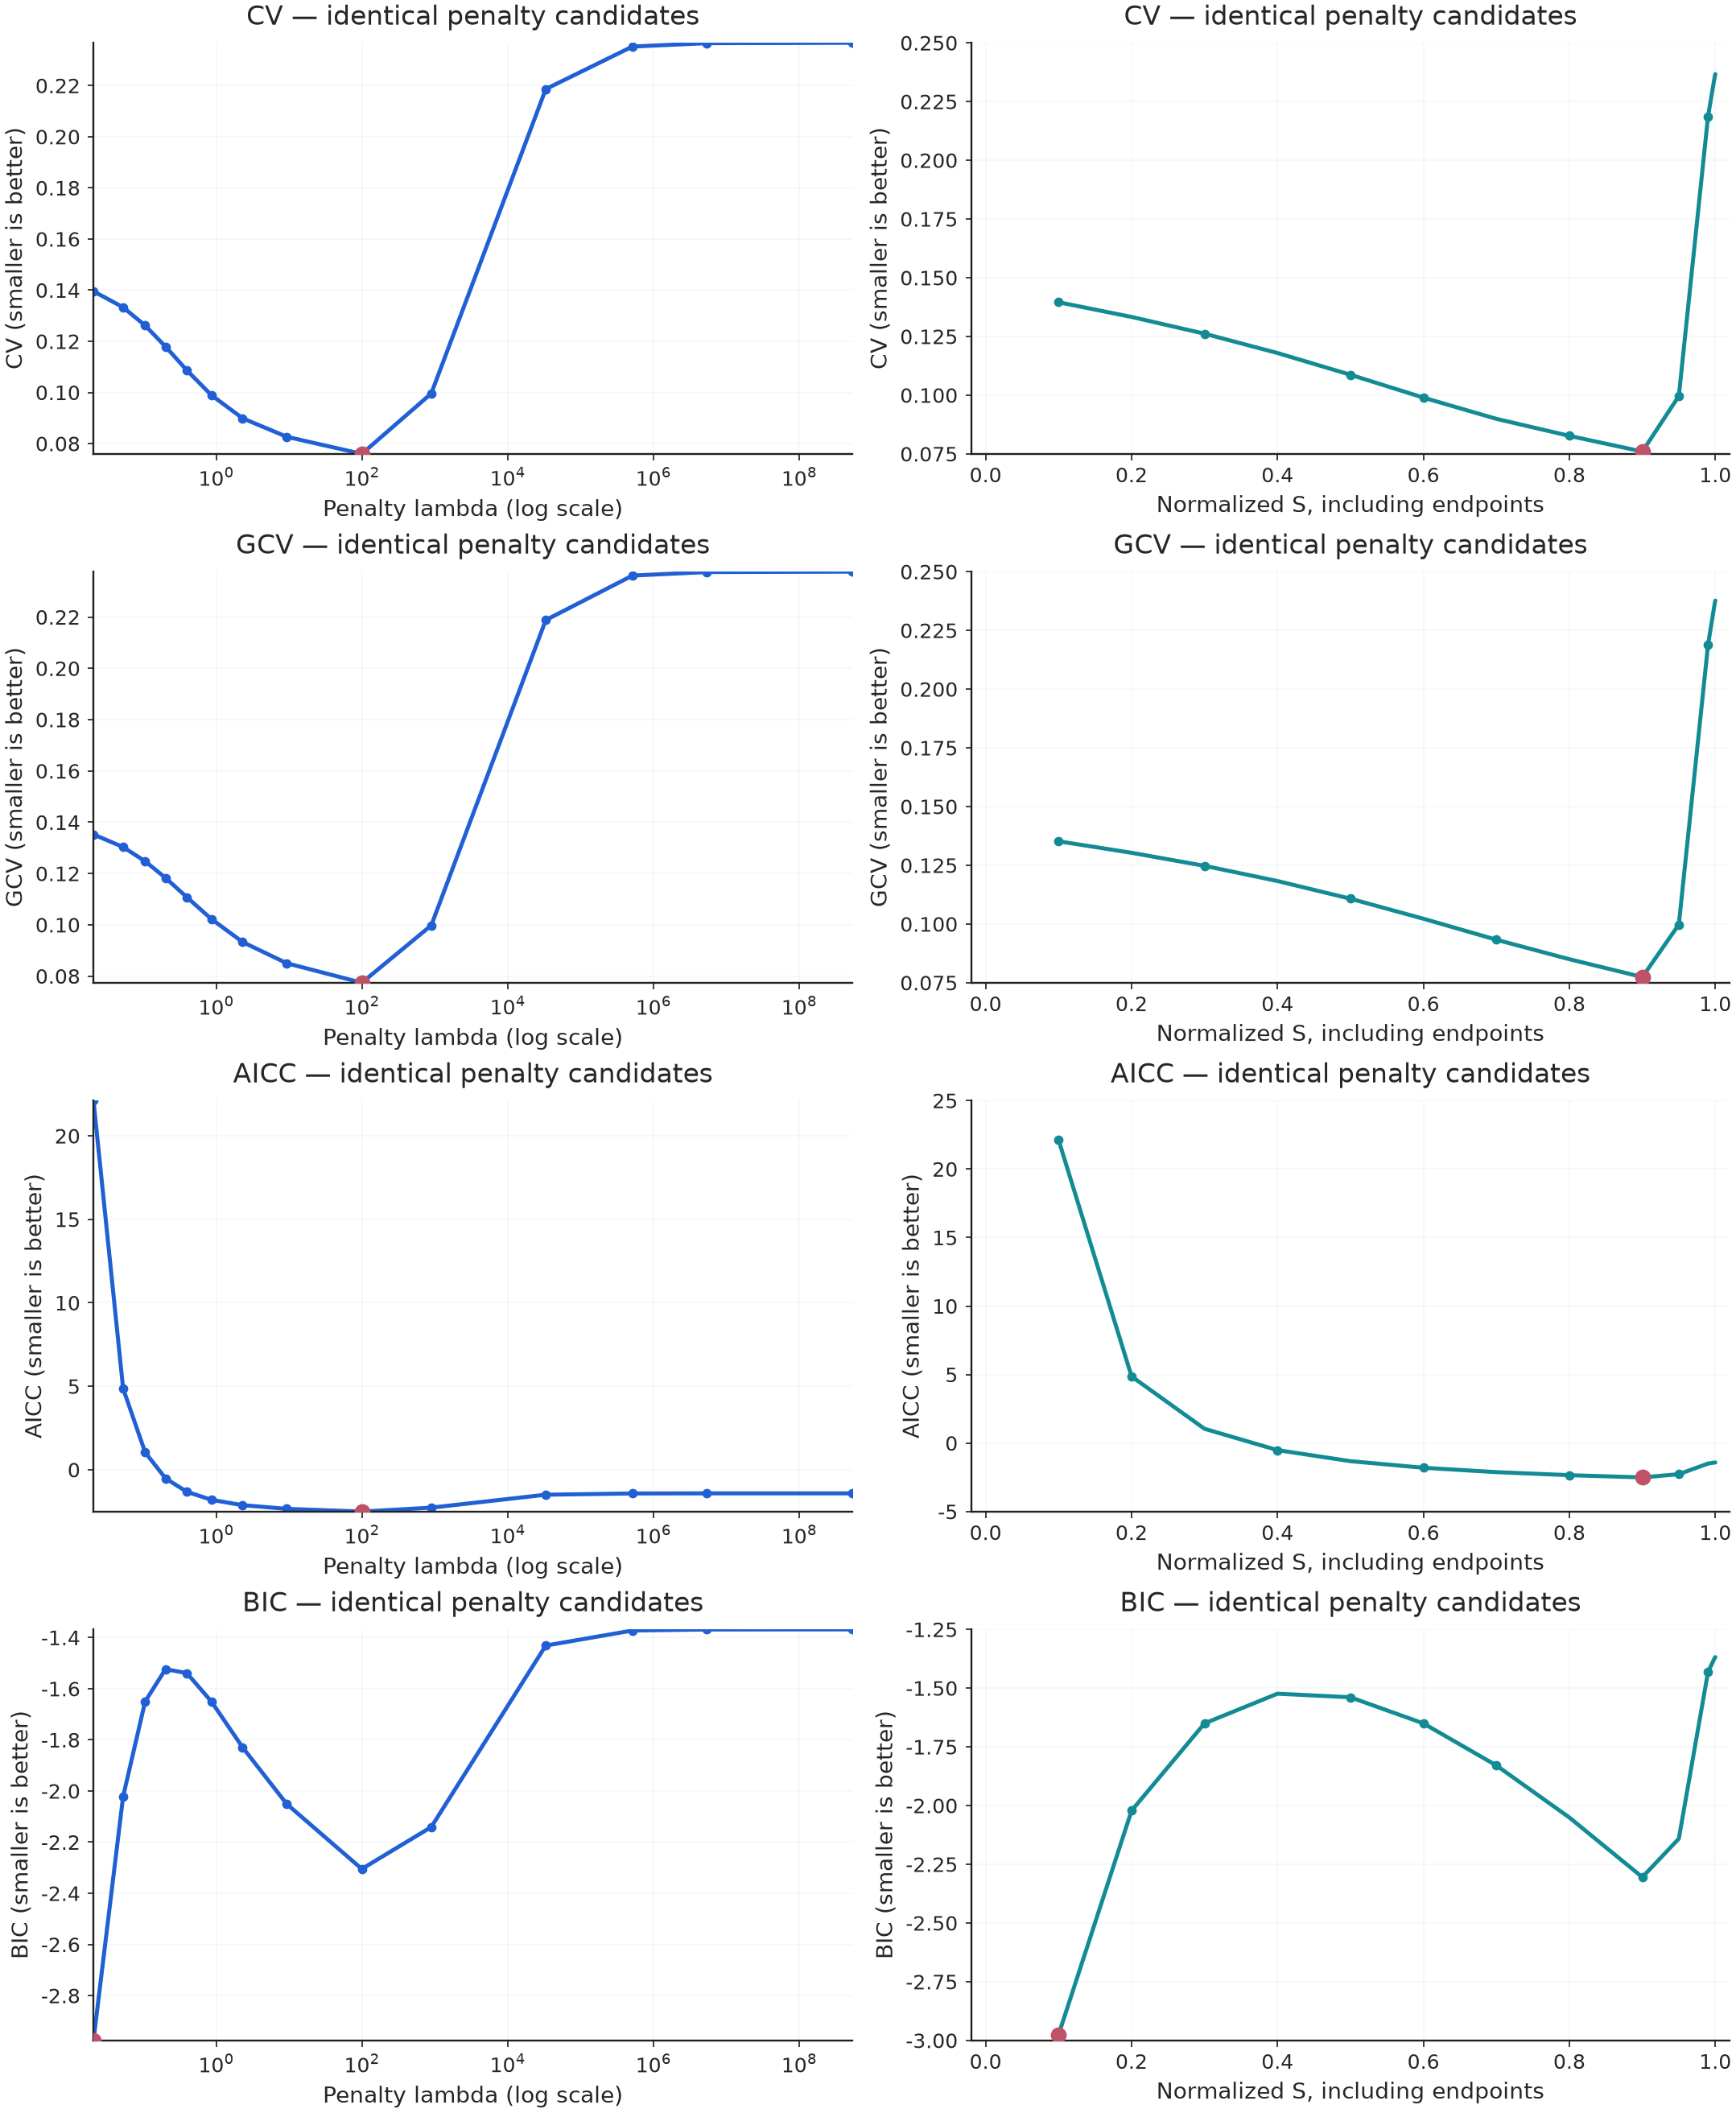

Left log-lambda plots omit 0 and infinity as coordinates, NOT as evaluated candidates. Right S plots include those endpoints. CV can be infinite at S=0 because unregularized LOOCV is undefined.


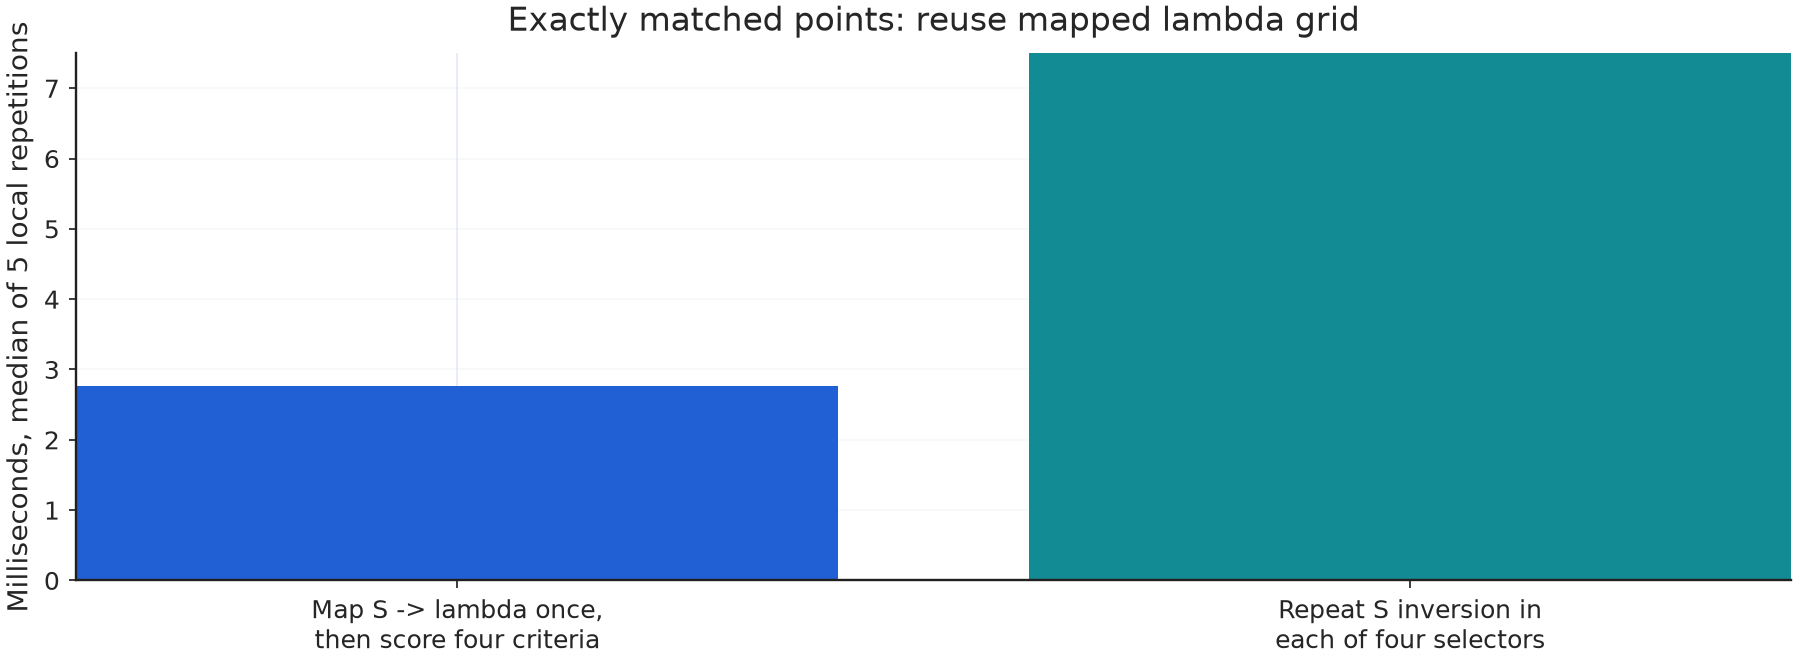

Four-criterion sweep, lambda-map-once: 2.771 ms; direct S selector (repeated mapping): 7.498 ms.
Both evaluate the same 16 penalties. This small, single-session measurement isolates a reusable-grid workflow, not the general speed of every optimization method or back end.


In [7]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

# Reuse notebook data when present; otherwise use a clearly labeled seeded example.
_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
